# Detecting mid-year changes, and using them to identify EV, HP and PV customers

Notebook 40 identified technology customers from features calculated over the **whole year**. A customer who installed solar panels in May, though, has eight months of ordinary use mixed into their yearly features, which **dilutes** their solar signature. This notebook asks:

1. **Can we detect when a customer's usage changed for good** during the year?
2. **Does measuring features only *after* that change** (the customer's "current period") help identify technology customers, as measured by AUC?

It builds on notebook 50:

- **Peer groups and the peer index** remove weather, season and calendar effects that customers share.
- **The stabilization length (about 4 weeks)** sets the minimum length of the "before" and "after" periods: a new pattern must last at least that long to count as a change.

### Outline

1. Daily peer-relative signals for every customer.
2. **General change detection**: any lasting shift in the 24-hour usage pattern.
3. **Technology-specific change detection**: a lasting rise in EV-like charging, a deeper solar midday dip, or more use in cold weather.
4. **Simulated adopters**: add realistic EV, PV or HP load to real customers from a known date, to test whether changes are detected and dated correctly.
5. **Feature-set comparison**: full-year features against current-period features, on (a) the real listed customers and (b) the simulated mid-year adopters.

Run from the project folder after notebooks 10–50. Peak memory use is about 5 GB, and the full notebook takes roughly 10 minutes.

## Setup

As in notebooks 40 and 50, `OMP_NUM_THREADS` is set to 1 before scikit-learn is imported, which keeps the many small gradient-boosting models fast on this machine.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import warnings
from datetime import timedelta

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', category=RuntimeWarning)

DB_PATH = 'onedrive-export/Data/avangrid.db'
CUSTOMER_GROUPS_PATH = 'onedrive-export/Data/EV_Heat Pump_Solar PV Customers.xlsx'
PLOT_DIR = 'onedrive-export/Data/eda'
TECHS = ['EV', 'PV', 'HP']
TECH_COLORS = {'EV': '#0072B2', 'PV': '#009E73', 'HP': '#E69F00'}

con = duckdb.connect(DB_PATH)
con.execute('SET enable_progress_bar = false')

STABILIZATION_DAYS = con.sql('SELECT ANY_VALUE(stabilization_days) FROM customer_stability').pl().item()
MIN_WEEKS = int(np.ceil(STABILIZATION_DAYS / 7))
print(f'Stabilization length from notebook 50: {STABILIZATION_DAYS} days -> minimum {MIN_WEEKS} weeks before and after a change')

Stabilization length from notebook 50: 24 days -> minimum 4 weeks before and after a change


## 1. Load hourly data

Two arrays of **customers × days × hours** are loaded for the customers in notebook 50's peer groups (everyone in `ami_analysis` except the 188 near-zero users):

- **`K`**: hourly kWh. Imputed hours are set to missing so they can't create or hide a change.
- **`P`**: the peer index (peer group × day × hour) from notebook 50.

Daily and hourly temperatures come from `weather_features`. The few missing temperatures are filled by interpolating between neighbouring hours.

In [2]:
customers = con.sql('SELECT CUSTOMER_NUMBER, peer_group, mean_kwh_real FROM customer_peer_groups ORDER BY 1').pl()
slots = con.sql('SELECT DISTINCT usage_date, hour_ending FROM peer_index ORDER BY 1, 2').pl()
START = slots['usage_date'].min()
slot_day = (slots['usage_date'] - START).dt.total_days().to_numpy()
slot_hour = slots['hour_ending'].to_numpy() - 1
N, N_DAYS = customers.height, int(slot_day.max()) + 1
N_WEEKS = N_DAYS // 7
group = customers['peer_group'].to_numpy()
mean_kwh = customers['mean_kwh_real'].to_numpy()

kwh = con.sql('''
    SELECT CASE WHEN a.is_imputed THEN NULL ELSE a.hourly_kwh END::FLOAT AS kwh
    FROM ami_analysis a SEMI JOIN customer_peer_groups USING (CUSTOMER_NUMBER)
    ORDER BY a.CUSTOMER_NUMBER, a.usage_date, a.hour_ending
''').pl()['kwh'].to_numpy()
K = np.full((N, N_DAYS, 24), np.nan, dtype=np.float32)
K[:, slot_day, slot_hour] = kwh.reshape(N, slots.height)
del kwh

pidx = con.sql('SELECT peer_group, usage_date, hour_ending, peer_n FROM peer_index').pl()
P = np.full((16, N_DAYS, 24), np.nan, dtype=np.float32)
P[pidx['peer_group'].to_numpy(), (pidx['usage_date'] - START).dt.total_days().to_numpy(),
  pidx['hour_ending'].to_numpy() - 1] = pidx['peer_n'].to_numpy()

wx = con.sql('SELECT usage_date, hour_ending, temp FROM weather_features ORDER BY 1, 2').pl()
temp_hourly = np.full((N_DAYS, 24), np.nan)
temp_hourly[(wx['usage_date'] - START).dt.total_days().to_numpy(), wx['hour_ending'].to_numpy() - 1] = wx['temp'].to_numpy()
flat = temp_hourly.ravel()
ok = ~np.isnan(flat)
flat[~ok] = np.interp(np.flatnonzero(~ok), np.flatnonzero(ok), flat[ok])
temp_hourly = flat.reshape(N_DAYS, 24)
temp_daily = temp_hourly.mean(axis=1)

sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')
listed = {tab.split()[0]: np.isin(customers['CUSTOMER_NUMBER'].to_numpy(), c['CUSTOMER_NUMBER'].to_numpy())
          for tab, c in sheets.items()}
any_listed = listed['EV'] | listed['HP'] | listed['PV']

week_start = [START + timedelta(days=7 * w) for w in range(N_WEEKS)]
print(f'{N:,} customers, {N_DAYS} days ({N_WEEKS} full weeks). Listed:', {t: int(v.sum()) for t, v in listed.items()})

33,310 customers, 365 days (52 full weeks). Listed: {'EV': 179, 'HP': 86, 'PV': 389}


## 2. Daily peer-relative signals

These are the same ideas as the features in notebook 40, but calculated **for each day**, so they can later be summed over any period. Each is relative to the customer's peer group on the same day, so seasons and weather that affect everyone cancel out.

| Signal | Meaning |
|---|---|
| `e_night`, `e_morning`, `e_afternoon`, `e_evening`, `e_midday`, `e_level` | Average peer-relative residual (use ÷ the customer's average, minus the peer index) in each time of day, at midday (`hour_ending` 11–15) and over the whole day |
| `n_mid`, `n_night`, `p_mid`, `p_night` | Normalized midday and night use for the customer and their peer group, used for the **midday dip** |
| `zero_mid_rel` | Share of midday hours under 0.05 kWh, minus the peer group's share that day |
| `high_hours_rel`, `sessions_rel`, `sharp_rises_rel` | EV-like counts per day (hours at least 3 kWh above the customer's usual use for that hour, runs of such hours, and jumps of 3+ kWh), minus the peer group's daily average |

The signals are computed by a function so the **same code** can be applied to the simulated adopters in section 4. The peer-group averages used for the relative signals (`refs`) are calculated once from real customers and reused for the simulated ones.

In [3]:
TOD_SLICES = {'night': slice(0, 6), 'morning': slice(6, 12), 'afternoon': slice(12, 18), 'evening': slice(18, 24)}
MIDDAY = slice(10, 15)          # hour_ending 11-15
EVENING_NIGHT = np.r_[0:6, 18:24]  # hour_ending 1-6 and 19-24


def group_relative(x, g, ref=None):
    # Subtract each peer group's daily mean (computed from x unless a reference is given).
    if ref is None:
        ref = np.vstack([np.nanmean(x[g == k], axis=0) for k in range(16)])
    return x - ref[g], ref


def daily_signals(Kx, g, mean_x, refs=None):
    n, nd, _ = Kx.shape
    refs = {} if refs is None else refs
    E = Kx / mean_x[:, None, None] - P[g]
    D = {f'e_{k}': np.nanmean(E[:, :, s], axis=2) for k, s in TOD_SLICES.items()}
    D['e_midday'] = np.nanmean(E[:, :, MIDDAY], axis=2)
    D['e_level'] = np.nanmean(E, axis=2)
    normalized = E + P[g]
    D['n_mid'] = np.nanmean(normalized[:, :, MIDDAY], axis=2)
    D['n_night'] = np.nanmean(normalized[:, :, TOD_SLICES['night']], axis=2)
    D['p_mid'] = np.nanmean(P[:, :, MIDDAY], axis=2)[g]
    D['p_night'] = np.nanmean(P[:, :, TOD_SLICES['night']], axis=2)[g]
    del E, normalized
    mid = Kx[:, :, MIDDAY]
    zero = np.nanmean(np.where(np.isnan(mid), np.nan, (mid < 0.05).astype(np.float32)), axis=2)
    base = np.nanmedian(Kx, axis=1)
    high = (Kx - base[:, None, :]) >= 3
    hf = high.reshape(n, -1)
    starts = hf & ~np.concatenate([np.zeros((n, 1), bool), hf[:, :-1]], axis=1)
    fl = Kx.reshape(n, -1)
    rises = np.concatenate([np.zeros((n, 1), bool), (fl[:, 1:] - fl[:, :-1]) >= 3], axis=1)
    for name, x in [('zero_mid_rel', zero), ('high_hours_rel', high.sum(2).astype(np.float32)),
                    ('sessions_rel', starts.reshape(n, nd, 24).sum(2).astype(np.float32)),
                    ('sharp_rises_rel', rises.reshape(n, nd, 24).sum(2).astype(np.float32))]:
        D[name], refs[name] = group_relative(x, g, refs.get(name))
    return D, refs


D, refs = daily_signals(K, group, mean_kwh)
print('Daily signals:', ', '.join(D))

Daily signals: e_night, e_morning, e_afternoon, e_evening, e_midday, e_level, n_mid, n_night, p_mid, p_night, zero_mid_rel, high_hours_rel, sessions_rel, sharp_rises_rel


## 3a. General change detection: any lasting shift in the daily pattern

A customer's **weekly pattern** is their average peer-relative residual at each of the 24 hours over the week. A lasting change shows up as a **step**: the weeks before a certain point look different from the weeks after it.

**Removing each customer's own weather response first.** Notebook 50 found that comparing with peers removes shared weather effects but not each household's *own* response. Without this step, the scan mostly "finds" the dates when individual households switched their air conditioning on. So, for each customer and each hour of the day, we fit their residual against temperature and remove it. The fit uses heating degrees below 55°F, extra terms below 35°F and 15°F for deep cold, cooling degrees above 65°F and 75°F for extreme heat, and a weekend flag. Fitting each temperature band separately lets the adjustment follow how use climbs faster in deep cold and extreme heat.

**The step statistic.** For every possible change week t, leaving at least `MIN_WEEKS` (the stabilization length) on each side, we compare the average weekly pattern before and after t. The statistic adds up the squared difference at each of the 24 hours, each divided by that hour's week-to-week variance, and weighted by the segment lengths. The week with the largest value is the most likely change week, and the value measures how strong the change is.

Weeks are correlated with each other, so the statistic can't be turned into an exact p-value. Instead we **flag the top 10%** of customers by change strength.

In [4]:
def change_scan(W, minw):
    # Diagonal step statistic for every split; the 'after' segment starts at week t.
    c, nw, h = W.shape
    W = np.where(np.isnan(W), np.nanmean(W, axis=1, keepdims=True), W)
    S1 = np.concatenate([np.zeros((c, 1, h)), np.cumsum(W, 1)], 1)
    S2 = np.concatenate([np.zeros((c, 1, h)), np.cumsum(W * W, 1)], 1)
    ts = np.arange(minw, nw - minw + 1)
    n1 = ts[None, :, None]; n2 = nw - n1
    s1, q1 = S1[:, ts], S2[:, ts]
    s2, q2 = S1[:, [nw]] - s1, S2[:, [nw]] - q1
    m1, m2 = s1 / n1, s2 / n2
    var = np.maximum(((q1 - n1 * m1 ** 2) + (q2 - n2 * m2 ** 2)) / (nw - 2), 1e-4)
    return ts, (n1[:, :, 0] * n2[:, :, 0] / nw) * ((m1 - m2) ** 2 / var).sum(2)


is_weekend = np.array([(START + timedelta(days=d)).weekday() >= 5 for d in range(N_DAYS)])
X_weather = np.column_stack([np.ones(N_DAYS),
                             np.maximum(55 - temp_daily, 0), np.maximum(35 - temp_daily, 0), np.maximum(15 - temp_daily, 0),
                             np.maximum(temp_daily - 65, 0), np.maximum(temp_daily - 75, 0), is_weekend]).astype(float)

E = K / mean_kwh[:, None, None] - P[group]
E_filled = np.where(np.isnan(E), np.nanmean(E, axis=1, keepdims=True), E).astype(np.float64)
beta = np.einsum('kd,cdh->ckh', np.linalg.pinv(X_weather), E_filled)
E_adj = (E_filled - np.einsum('dk,ckh->cdh', X_weather, beta)).astype(np.float32)
E_adj[np.isnan(E)] = np.nan
del E, E_filled
weekly_pattern = np.nanmean(E_adj[:, :N_WEEKS * 7].reshape(N, N_WEEKS, 7, 24), axis=2).astype(np.float64)
del E_adj

split_weeks, T = change_scan(weekly_pattern, MIN_WEEKS)
general_strength = T.max(axis=1)
general_week = split_weeks[T.argmax(axis=1)]
GENERAL_THRESHOLD = np.quantile(general_strength, 0.90)
general_flag = general_strength >= GENERAL_THRESHOLD

print(f'Flagged {general_flag.sum():,} customers ({general_flag.mean():.0%}) with a strong general change.')
print('Share of each group flagged:', {t: round(float(general_flag[listed[t]].mean()), 3) for t in TECHS},
      '| not listed:', round(float(general_flag[~any_listed].mean()), 3))

Flagged 3,331 customers (10%) with a strong general change.
Share of each group flagged: {'EV': 0.073, 'PV': 0.1, 'HP': 0.116} | not listed: 0.1


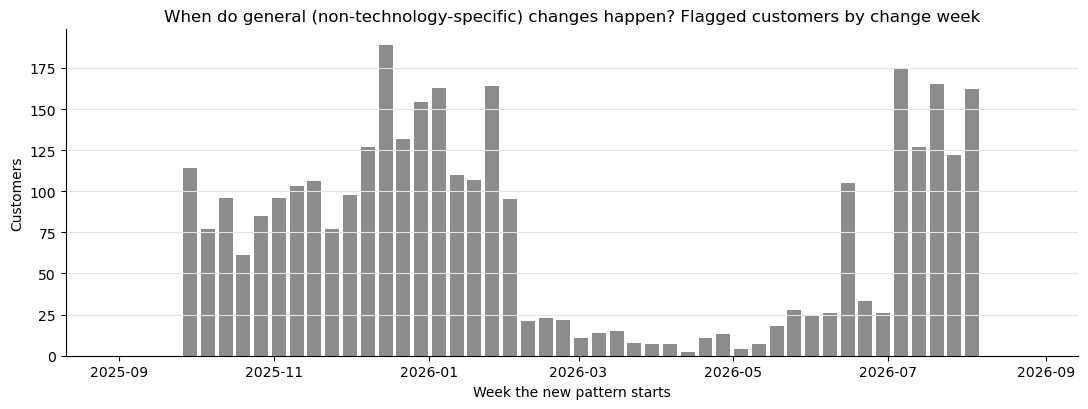

In [5]:
counts = np.bincount(general_week[general_flag], minlength=N_WEEKS)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(week_start, counts, width=5.5, color='#8c8c8c')
ax.set_title('When do general (non-technology-specific) changes happen? Flagged customers by change week')
ax.set_ylabel('Customers')
ax.set_xlabel('Week the new pattern starts')
ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/general_change_weeks.png', dpi=150)
plt.show()

**What general changes capture.** Even after removing each customer's weather response, flagged changes cluster in **autumn to mid-winter** and in **July–August**. These are probably changes in *occupancy and routine*: students moving in, the holiday season, seasonal residents, summer holidays and summer homes. They are real, lasting changes in usage, but mostly **not technology adoption**. The listed EV, HP and PV customers are flagged at about the same rate as everyone else, so a general change isn't a useful sign of adoption.

The rest of the notebook therefore uses **technology-specific** change detection, which looks only at the part of the usage pattern each technology affects.

## 3b. Technology-specific change detection

Each technology gets one **weekly signal**, oriented so that adopting the technology makes it go **up**:

| Technology | Weekly signal | Weeks scanned |
|---|---|---|
| **EV** | kWh above the customer's usual (median) use for that hour, counting only hours at least 2.5 kWh above it, in the **evening and overnight** (`hour_ending` 19–6), when most home charging happens. Then adjusted for each customer's weekly response to heating and cooling degrees | All weeks |
| **PV** | Depth of the midday dip: night residual minus midday residual. Solar generation lowers grid use at midday only | All weeks |
| **HP** | Overall peer-relative level (`e_level`). A heat pump adds load in cold weather | Only weeks averaging **under 45°F** (Nov–Mar), where a heating change can show |

The EV signal was chosen after testing several options on simulated EV adopters (section 4). Weather-adjusted evening and overnight kWh caught clearly more simulated adopters than daily session counts, which also rise with electric heating in winter.

**The step scan.** For each split point, leaving at least `MIN_WEEKS` weeks on each side, we compare the average signal after the split with the average before it, as a t-statistic (z). The split with the largest z is the most likely change week.

**Threshold.** A customer is flagged if their largest z is above the **95th percentile among customers on none of the lists**. Most of those customers never adopted anything, so this allows roughly a 5% false-flag rate. Section 4 measures how many real adoptions this threshold catches.

In [6]:
def weekly(x, nw=N_WEEKS):
    return np.nanmean(x[:, :nw * 7].reshape(x.shape[0], nw, 7), axis=2)


temp_weekly = weekly(temp_daily[None, :])[0]
X_weekly_weather = np.column_stack([np.ones(N_WEEKS), np.maximum(55 - temp_weekly, 0), np.maximum(temp_weekly - 65, 0)])


def remove_weekly_weather(Y):
    beta = np.linalg.pinv(X_weekly_weather) @ np.nan_to_num(Y).T
    return Y - (X_weekly_weather @ beta).T


def ev_weekly_signal(Kx):
    excess = Kx - np.nanmedian(Kx, axis=1)[:, None, :]
    evening_night = excess[:, :, EVENING_NIGHT]
    daily_kwh = np.nansum(np.where(evening_night >= 2.5, evening_night, 0), axis=2)
    return remove_weekly_weather(weekly(daily_kwh))


def tech_weekly_signals(Dx, Kx):
    return {'EV': ev_weekly_signal(Kx),
            'PV': -weekly(Dx['e_midday'] - Dx['e_night']),
            'HP': weekly(Dx['e_level'])}


SCAN_WEEKS = {'EV': np.arange(N_WEEKS), 'PV': np.arange(N_WEEKS), 'HP': np.flatnonzero(temp_weekly < 45)}


def step_scan(x, weeks, minw):
    x = x[:, weeks]
    x = np.where(np.isnan(x), np.nanmean(x, axis=1, keepdims=True), x)
    n = x.shape[1]
    S1 = np.concatenate([np.zeros((x.shape[0], 1)), np.cumsum(x, 1)], 1)
    S2 = np.concatenate([np.zeros((x.shape[0], 1)), np.cumsum(x * x, 1)], 1)
    ts = np.arange(minw, n - minw + 1)
    n1, n2 = ts[None, :], n - ts[None, :]
    m1 = S1[:, ts] / n1
    m2 = (S1[:, [n]] - S1[:, ts]) / n2
    ss = (S2[:, ts] - n1 * m1 ** 2) + ((S2[:, [n]] - S2[:, ts]) - n2 * m2 ** 2)
    sp = np.sqrt(np.maximum(ss / (n - 2), 1e-8))
    z = (m2 - m1) / (sp * np.sqrt(1 / n1 + 1 / n2))
    return weeks[ts], z


def scan_tech(signal, tech):
    wk, z = step_scan(signal, SCAN_WEEKS[tech], MIN_WEEKS)
    return z.max(axis=1), wk[z.argmax(axis=1)]


signals = tech_weekly_signals(D, K)
scan = {}
for tech in TECHS:
    zmax, zweek = scan_tech(signals[tech], tech)
    threshold = np.quantile(zmax[~any_listed], 0.95)
    scan[tech] = {'z': zmax, 'week': zweek, 'threshold': threshold, 'flag': zmax >= threshold}

print(f"HP scan covers weeks starting {week_start[SCAN_WEEKS['HP'][0]]} to {week_start[SCAN_WEEKS['HP'][-1]]}")
summary_rows = []
for tech in TECHS:
    s = scan[tech]
    summary_rows.append({'technology': tech, 'z_threshold': round(float(s['threshold']), 2),
                         'flagged_all': int(s['flag'].sum()),
                         'share_flagged_not_listed': round(float(s['flag'][~any_listed].mean()), 3),
                         f'share_flagged_listed': round(float(s['flag'][listed[tech]].mean()), 3)})
pl.DataFrame(summary_rows)

HP scan covers weeks starting 2025-10-27 to 2026-04-06


technology,z_threshold,flagged_all,share_flagged_not_listed,share_flagged_listed
str,f64,i64,f64,f64
"""EV""",3.86,1681,0.05,0.089
"""PV""",8.01,1705,0.05,0.157
"""HP""",6.46,1650,0.05,0.058


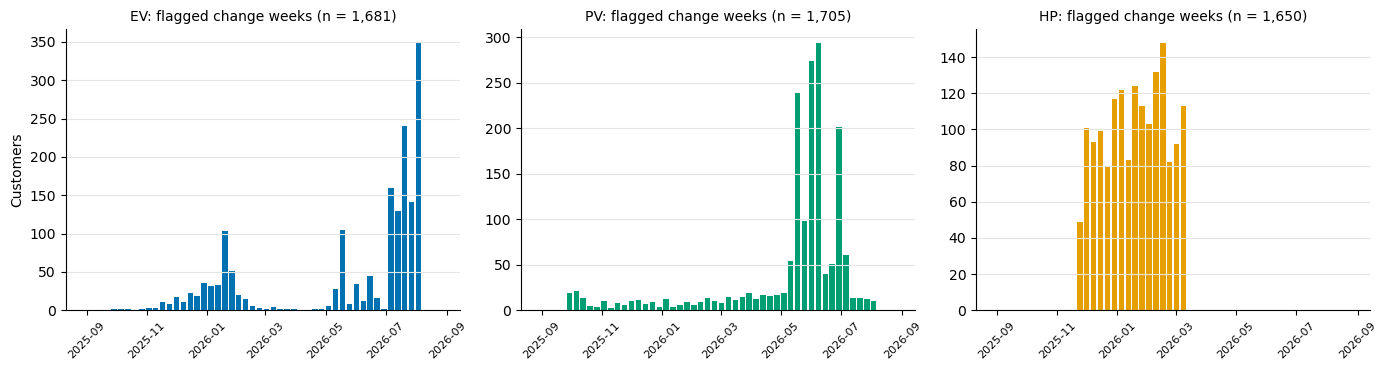

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, tech in zip(axes, TECHS):
    s = scan[tech]
    counts = np.bincount(s['week'][s['flag']], minlength=N_WEEKS)
    ax.bar(week_start, counts, width=5.5, color=TECH_COLORS[tech])
    ax.set_title(f'{tech}: flagged change weeks (n = {s["flag"].sum():,})', fontsize=10)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
    ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Customers')
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/tech_change_weeks.png', dpi=150)
plt.show()

The share of **listed** customers flagged for their own technology shows whether the lists contain many mid-year adopters. Shares close to the 5% false-flag rate would mean that most listed customers had the technology before September 2025, so there's no "before" period diluting their features.

## 4. Simulated mid-year adopters

There are no confirmed adoption dates, so we create adopters with **known** dates. We take 300 random customers on none of the lists and, from a random week between November and late July (weeks 8–44), modify their hourly kWh:

- **EV**: add the charging-like load of a randomly chosen *listed* EV customer (hours where that customer is at least 3 kWh above their own usual use for that hour, with the amount above it). This copies real charging timing and size.
- **PV**: subtract a simulated solar generation curve. Generation is shaped by day length and season, multiplied by random daily cloudiness (20–100%), with a random system size that produces 2–6 kWh in the peak hour. Grid use can't go below zero, matching the meter data.
- **HP**: add extra heating load of b × (degrees below 55°F) each hour, with b drawn between 0.01 and 0.03 kWh per degree-hour. That is in line with the difference in heating slope between listed HP customers and others in notebook 40.

The simulated customers go through **exactly the same pipeline** (daily signals, weekly signal, step scan, same threshold) as real ones. We measure:

- **Detected**: share of simulated adopters flagged.
- **Control**: share of the same 300 customers flagged *without* the added load, the false-flag rate for those customers.
- **Week error**: for detected adopters, the gap between the estimated and true change week.

To avoid leaking information, EV charging is only copied from **half** of the listed EV customers. The other half are used for training in section 5. The same split is used for PV and HP for consistency.

In [8]:
N_SIM = 300
rng = np.random.default_rng(5)
doy = np.array([(START + timedelta(days=d)).timetuple().tm_yday for d in range(N_DAYS)])
day_length = 12 + 3 * np.sin(2 * np.pi * (doy - 80) / 365)
sunrise = 12.5 - day_length / 2
hour_mid = np.arange(24) + 0.5
solar_shape = (np.clip(np.sin(np.pi * (hour_mid[None, :] - sunrise[:, None]) / day_length[:, None]), 0, None)
               * (0.65 + 0.35 * np.sin(2 * np.pi * (doy - 80) / 365))[:, None])

sim = {}
for tech in TECHS:
    pos = rng.permutation(np.flatnonzero(listed[tech]))
    train_pos, donor_pool = pos[:len(pos) // 2], pos[len(pos) // 2:]
    recipients = rng.choice(np.flatnonzero(~any_listed), N_SIM, replace=False)
    true_week = rng.integers(8, 45, N_SIM)
    after = (np.arange(N_DAYS)[None, :] >= (true_week * 7)[:, None])[:, :, None]
    Ks = K[recipients].astype(np.float64)
    if tech == 'EV':
        donors = rng.choice(donor_pool, N_SIM)
        excess = K[donors] - np.nanmedian(K[donors], axis=1)[:, None, :]
        Ks = Ks + np.where(after, np.nan_to_num(np.where(excess >= 3, excess, 0)), 0)
    elif tech == 'PV':
        size = rng.uniform(2, 6, N_SIM)
        cloud = rng.uniform(0.2, 1.0, (N_SIM, N_DAYS))
        generation = size[:, None, None] * solar_shape[None] * cloud[:, :, None]
        Ks = np.where(after, np.maximum(Ks - generation, 0), Ks)
    else:
        b = rng.uniform(0.01, 0.03, N_SIM)
        Ks = Ks + np.where(after, b[:, None, None] * np.maximum(55 - temp_hourly, 0)[None], 0)
    Ks = Ks.astype(np.float32)
    mean_s = np.nanmean(Ks.reshape(N_SIM, -1), axis=1)
    Ds, _ = daily_signals(Ks, group[recipients], mean_s, refs)
    z_s, week_s = scan_tech(tech_weekly_signals(Ds, Ks)[tech], tech)
    detected = z_s >= scan[tech]['threshold']
    sim[tech] = dict(train_pos=train_pos, donor_pool=donor_pool, recipients=recipients, true_week=true_week,
                     D=Ds, mean=mean_s, z=z_s, week=week_s, detected=detected)
    del Ks

detection = pl.DataFrame([{
    'technology': t,
    'detected': round(float(sim[t]['detected'].mean()), 3),
    'control_flagged': round(float(scan[t]['flag'][sim[t]['recipients']].mean()), 3),
    'median_week_error': float(np.median(np.abs(sim[t]['week'] - sim[t]['true_week'])[sim[t]['detected']])),
    'share_within_2_weeks': round(float(np.mean(np.abs(sim[t]['week'] - sim[t]['true_week'])[sim[t]['detected']] <= 2)), 3),
} for t in TECHS])
detection

technology,detected,control_flagged,median_week_error,share_within_2_weeks
str,f64,f64,f64,f64
"""EV""",0.313,0.023,0.0,0.67
"""PV""",0.777,0.027,0.0,0.82
"""HP""",0.287,0.033,0.0,0.93


**What the simulation shows about detection:**

- **PV adoption is detected reliably**, usually in exactly the right week. Solar changes the midday dip clearly and doesn't depend on human behaviour.
- **Heat pumps are detected less often.** The change only shows in cold weeks, and adopting in late winter leaves few cold weeks afterwards. When detected, the date is usually accurate.
- **EV adoption is hard to detect from hourly data.** The charging copied from listed EV customers is small, typically under 10 kWh a week against well over 100 kWh of total use, and it's irregular. That is consistent with notebook 40, where EV was much harder to identify than PV, and suggests many listed EV customers charge slowly or away from home.

## 5. Do current-period features improve identification?

For each technology we compare four feature sets, all with the same bagging PU model as notebook 40 (gradient boosting, 20 models):

| Set | Features |
|---|---|
| **A** | Notebook 40's full-year features (absolute values, from `customer_features`). Real customers only |
| **B** | The peer-relative features below, calculated over the **full year** |
| **C1** | The same peer-relative features calculated over the **current period**: from the detected change week (for that technology) to the end of the year, or the full year if no change was flagged |
| **C2** | C1, plus the **change itself**: the after-minus-before difference in each feature, whether a change was flagged, the length of the current period, and the change strength (z) |

**Peer-relative features for any period:** average residual in each time of day, at midday and overall; midday dip relative to peers; near-zero midday share; EV-like counts; heating and cooling slopes of daily residual level against degrees (each needing at least 14 heating or cooling days in the period); average residual on days below 35°F; and the log of average use. They're computed from running totals of the daily signals, so any start and end date per customer takes the same, fast calculation.

B against C1 isolates the effect of **using only the current period**, since the feature definitions are identical. A shows how notebook 40's features compare.

In [9]:
DAILY_MEANS = ['e_night', 'e_morning', 'e_afternoon', 'e_evening', 'e_midday', 'e_level',
               'zero_mid_rel', 'high_hours_rel', 'sessions_rel', 'sharp_rises_rel']


def running_totals(Dx):
    def cs(x):
        v = np.where(np.isnan(x), 0, x); c = (~np.isnan(x)).astype(float)
        z = np.zeros((x.shape[0], 1))
        return np.concatenate([z, np.cumsum(v, 1)], 1), np.concatenate([z, np.cumsum(c, 1)], 1)
    n, nd = Dx['e_level'].shape
    C = {k: cs(Dx[k]) for k in DAILY_MEANS + ['n_mid', 'n_night', 'p_mid', 'p_night']}
    level = Dx['e_level']
    for name, x in [('heat', np.maximum(55 - temp_daily, 0)), ('cool', np.maximum(temp_daily - 65, 0))]:
        mask = np.where(x > 0, 1.0, np.nan)
        xx = np.broadcast_to(x * mask, (n, nd)); y = level * mask
        valid = np.where(np.isnan(y), np.nan, 1.0)
        for suffix, arr in [('n', valid), ('x', xx * valid), ('xx', xx * xx * valid), ('y', y), ('xy', xx * y)]:
            C[f'{name}_{suffix}'] = cs(arr)
    C['cold_y'] = cs(np.where(np.broadcast_to(temp_daily < 35, (n, nd)), level, np.nan))
    return C


def period_features(C, d0, d1):
    n = C['e_level'][0].shape[0]; r = np.arange(n)
    d0 = np.broadcast_to(d0, (n,)).astype(int); d1 = np.broadcast_to(d1, (n,)).astype(int)
    seg = lambda k, i=0: C[k][i][r, d1] - C[k][i][r, d0]
    mean = lambda k: np.where(seg(k, 1) > 0, seg(k) / np.maximum(seg(k, 1), 1), np.nan)
    f = {k: mean(k) for k in DAILY_MEANS}
    f['dip_rel'] = mean('n_mid') / mean('n_night') - mean('p_mid') / mean('p_night')
    for name in ['heat', 'cool']:
        k, sx, sxx, sy, sxy = (seg(f'{name}_{s}') for s in ['n', 'x', 'xx', 'y', 'xy'])
        den = k * sxx - sx ** 2
        f[f'{name}_slope_rel'] = np.where((k >= 14) & (den > 0), (k * sxy - sx * sy) / np.where(den > 0, den, 1), np.nan)
    cy, cn = seg('cold_y'), seg('cold_y', 1)
    f['cold_level_rel'] = np.where(cn >= 5, cy / np.maximum(cn, 1), np.nan)
    return f


def feature_sets(C, change_day, has_change, z, log_mean):
    full = period_features(C, 0, N_DAYS)
    current = period_features(C, change_day, N_DAYS)
    before = period_features(C, 0, np.maximum(change_day, 1))
    names = list(full)
    B = np.column_stack([full[k] for k in names] + [log_mean])
    C1 = np.column_stack([current[k] for k in names] + [log_mean])
    C2 = np.column_stack([C1] + [np.where(has_change, current[k] - before[k], 0) for k in names]
                         + [has_change, (N_DAYS - change_day) / 7, z])
    out = {'B: full year': B, 'C1: current period': C1, 'C2: current period + change': C2}
    for v in out.values():
        v[~np.isfinite(v)] = np.nan
    return out


def bagging_pu(X, labeled, seed, X_extra=None, n_models=20, neg_ratio=10):
    rng = np.random.default_rng(seed)
    pos, unl = np.flatnonzero(labeled), np.flatnonzero(~labeled)
    k = min(len(unl), neg_ratio * len(pos))
    total, count = np.zeros(len(labeled)), np.zeros(len(labeled))
    extra = None if X_extra is None else np.zeros(len(X_extra))
    for b in range(n_models):
        sample = rng.choice(unl, k, replace=False)
        idx = np.r_[pos, sample]
        y = np.r_[np.ones(len(pos)), np.zeros(k)]
        model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                               random_state=seed * 1000 + b).fit(X[idx], y)
        oob = np.setdiff1d(unl, sample)
        total[oob] += model.predict_proba(X[oob])[:, 1]; count[oob] += 1
        if X_extra is not None:
            extra += model.predict_proba(X_extra)[:, 1] / n_models
    return np.where(count > 0, total / np.maximum(count, 1), np.nan), extra


C_real = running_totals(D)
log_mean_real = np.log(mean_kwh)
real_sets = {}
for tech in TECHS:
    s = scan[tech]
    change_day = np.where(s['flag'], s['week'] * 7, 0)
    real_sets[tech] = feature_sets(C_real, change_day, s['flag'], s['z'], log_mean_real)

cf = con.sql('SELECT * FROM customer_features').pl()
A = (customers.select('CUSTOMER_NUMBER').join(cf, on='CUSTOMER_NUMBER', how='left')
     .drop('CUSTOMER_NUMBER').to_numpy().astype(float))
A[~np.isfinite(A)] = np.nan
print('Feature counts:', {'A': A.shape[1]} | {k: v.shape[1] for k, v in real_sets['PV'].items()})

Feature counts: {'A': 23, 'B: full year': 15, 'C1: current period': 15, 'C2: current period + change': 32}


### 5a. Real listed customers (hidden-label test)

As in notebook 40: some listed customers are hidden among the unlabeled, and we measure how well each feature set ranks them above customers on none of the lists (AUC).

- **PV**: 3 runs, each keeping a random 25% of PV customers labeled (mimicking the EV and HP lists).
- **EV and HP**: 5-fold cross-validation. Each fold hides 20% of the listed customers and trains on the rest.

We also count how many hidden customers had a detected change for that technology, since only they can benefit from current-period features. This cell takes about 5 minutes.

In [10]:
real_rows = []
for tech in TECHS:
    pos = np.flatnonzero(listed[tech])
    if tech == 'PV':
        splits = []
        for r in range(3):
            lab = np.zeros(N, bool)
            lab[np.random.default_rng(100 + r).choice(pos, round(0.25 * len(pos)), replace=False)] = True
            splits.append((r, lab))
    else:
        folds = np.array_split(np.random.default_rng(7).permutation(pos), 5)
        splits = [(r, np.isin(np.arange(N), np.setdiff1d(pos, fold))) for r, fold in enumerate(folds)]
    for r, lab in splits:
        hidden = listed[tech] & ~lab
        evaluate = hidden | ~any_listed
        y = hidden[evaluate]
        for name, X in ({'A: notebook 40': A} | real_sets[tech]).items():
            score, _ = bagging_pu(X, lab, r)
            real_rows.append({'technology': tech, 'run': r, 'feature_set': name,
                              'auc': roc_auc_score(y, score[evaluate]),
                              'hidden': int(y.sum()), 'hidden_with_change': int((hidden & scan[tech]['flag']).sum())})

real_results = (pl.DataFrame(real_rows)
                .group_by('technology', 'feature_set', maintain_order=True)
                .agg(pl.col('auc').mean().round(3).alias('auc_mean'), pl.col('auc').std().round(3).alias('auc_sd'),
                     pl.col('hidden').sum().alias('hidden_total'), pl.col('hidden_with_change').sum().alias('hidden_with_change')))
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True):
    print(real_results)

┌────────────┬─────────────────────────────┬──────────┬────────┬──────────────┬────────────────────┐
│ technology ┆ feature_set                 ┆ auc_mean ┆ auc_sd ┆ hidden_total ┆ hidden_with_change │
│ ---        ┆ ---                         ┆ ---      ┆ ---    ┆ ---          ┆ ---                │
│ str        ┆ str                         ┆ f64      ┆ f64    ┆ i64          ┆ i64                │
╞════════════╪═════════════════════════════╪══════════╪════════╪══════════════╪════════════════════╡
│ EV         ┆ A: notebook 40              ┆ 0.756    ┆ 0.037  ┆ 179          ┆ 16                 │
│ EV         ┆ B: full year                ┆ 0.679    ┆ 0.046  ┆ 179          ┆ 16                 │
│ EV         ┆ C1: current period          ┆ 0.677    ┆ 0.057  ┆ 179          ┆ 16                 │
│ EV         ┆ C2: current period + change ┆ 0.683    ┆ 0.057  ┆ 179          ┆ 16                 │
│ PV         ┆ A: notebook 40              ┆ 0.971    ┆ 0.001  ┆ 876          ┆ 137        

### 5b. Simulated mid-year adopters

Here the true adoption dates are known. For each technology, the model is trained on real customers, using half of the listed customers as labeled positives. It then scores:

- the **300 simulated adopters**, each scored by all models and averaged, since none were used in training;
- the **held-out half** of the listed customers;
- customers on **none of the lists**, the comparison group.

AUC is calculated for each of the first two groups against the comparison group, and for simulated adopters split by **when** they adopted. Later adopters have more diluted full-year features, so that's where current-period features should help most.

In [11]:
PERIODS = {'Oct–Nov': (8, 13), 'Dec–Feb': (13, 26), 'Mar–May': (26, 39), 'Jun–Jul': (39, 45)}
sim_rows = []
for tech in TECHS:
    sm, s = sim[tech], scan[tech]
    D_all = {k: np.vstack([D[k], sm['D'][k]]) for k in D}
    C_all = running_totals(D_all)
    change_day = np.r_[np.where(s['flag'], s['week'] * 7, 0), np.where(sm['detected'], sm['week'] * 7, 0)]
    has_change = change_day > 0
    sets = feature_sets(C_all, change_day, has_change, np.r_[s['z'], sm['z']], np.log(np.r_[mean_kwh, sm['mean']]))
    lab = np.zeros(N, bool); lab[sm['train_pos']] = True
    comparison = ~any_listed
    for name, X in sets.items():
        score, sim_score = bagging_pu(X[:N], lab, 0, X_extra=X[N:])
        base = score[comparison]
        auc = lambda pos_scores: roc_auc_score(np.r_[np.ones(len(pos_scores)), np.zeros(len(base))], np.r_[pos_scores, base])
        row = {'technology': tech, 'feature_set': name,
               'simulated_adopters': auc(sim_score), 'held_out_listed': auc(score[sm['donor_pool']])}
        for p, (lo, hi) in PERIODS.items():
            row[f'adopted_{p}'] = auc(sim_score[(sm['true_week'] >= lo) & (sm['true_week'] < hi)])
        sim_rows.append(row)
    del D_all, C_all

sim_results = pl.DataFrame(sim_rows).with_columns(pl.selectors.float().round(3))
with pl.Config(tbl_cols=-1, tbl_rows=-1, tbl_hide_dataframe_shape=True):
    print(sim_results)

┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ technology ┆ feature_se ┆ simulated_ ┆ held_out_ ┆ adopted_O ┆ adopted_D ┆ adopted_M ┆ adopted_J │
│ ---        ┆ t          ┆ adopters   ┆ listed    ┆ ct–Nov    ┆ ec–Feb    ┆ ar–May    ┆ un–Jul    │
│ str        ┆ ---        ┆ ---        ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│            ┆ str        ┆ f64        ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ EV         ┆ B: full    ┆ 0.658      ┆ 0.712     ┆ 0.785     ┆ 0.723     ┆ 0.589     ┆ 0.569     │
│            ┆ year       ┆            ┆           ┆           ┆           ┆           ┆           │
│ EV         ┆ C1:        ┆ 0.674      ┆ 0.71      ┆ 0.778     ┆ 0.731     ┆ 0.603     ┆ 0.627     │
│            ┆ current    ┆            ┆           ┆           ┆           ┆           ┆   

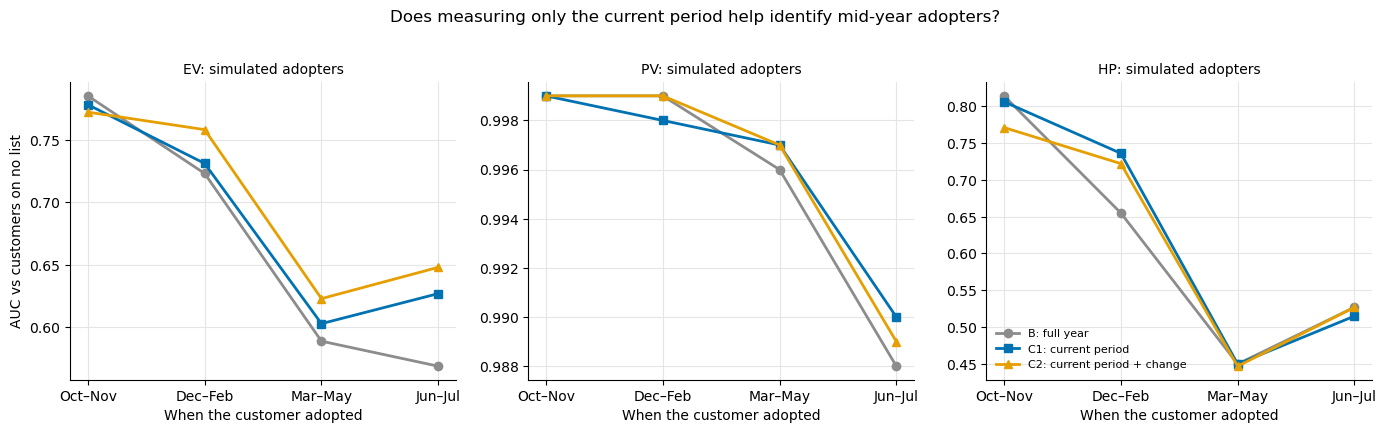

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
set_styles = {'B: full year': ('#8c8c8c', 'o'), 'C1: current period': ('#0072B2', 's'), 'C2: current period + change': ('#E69F00', '^')}
period_cols = [f'adopted_{p}' for p in PERIODS]
for ax, tech in zip(axes, TECHS):
    for name, (color, marker) in set_styles.items():
        row = sim_results.filter((pl.col('technology') == tech) & (pl.col('feature_set') == name)).row(0, named=True)
        ax.plot(list(PERIODS), [row[c] for c in period_cols], color=color, marker=marker, linewidth=2, label=name)
    ax.set_title(f'{tech}: simulated adopters', fontsize=10)
    ax.set_xlabel('When the customer adopted')
    ax.grid(color='#e5e5e5', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('AUC vs customers on no list')
axes[-1].legend(frameon=False, fontsize=8, loc='lower left')
fig.suptitle('Does measuring only the current period help identify mid-year adopters?', y=1.02)
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/current_period_auc.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Results

**Real listed customers (5a).** Current-period features give **no measurable gain**. Few listed customers have a detected change for their technology (see the `hidden_with_change` column), so there's little dilution to remove. Most listed customers appear to have had their technology for the whole year. Notebook 40's full-year features (A) remain the best or joint best, and switching to the current period costs little for customers without a change.

**Simulated mid-year adopters (5b).** When adoption happens during the year **and the change is detected**, current-period features help:

- **Heat pumps**: the clearest gain, especially for **winter adopters**. A full-year heating slope mixes months without the heat pump with months with it; the current-period slope measures it directly.
- **PV**: already near-perfect, with a small gain for **late (summer) adopters**, whose full-year features are most diluted.
- **EV**: no gain, because EV changes are rarely detected, so current-period features rarely differ from full-year ones.

Adding the change itself (C2) doesn't consistently beat the current period alone (C1). The change features add noise for the many customers without a real change.

### Answer to the question

Restricting features to the period after a major change **can** improve identification, but only for customers who really adopted mid-year and whose change is detectable (mainly heat pumps and solar). The listed customers mostly don't fit that description, so the AUC measured on them doesn't improve. In practice:

- Use **notebook 40's full-year model** as the main ranking.
- Use **technology-specific change detection** to flag likely **new adopters**, especially solar (reliable, well-dated) and heat pumps in winter. For flagged customers, rank them with **current-period features**.
- Don't rely on hourly data alone to date EV adoption.

## 7. Save the change points

**`change_points`** (one row per customer) records, for the general scan and each technology: the most likely change week (as a date), its strength, and whether it passed the threshold. A CSV of customers flagged for any technology is also saved for review, with whether they're already on that technology's list.

In [13]:
cp = customers.select('CUSTOMER_NUMBER').with_columns(
    pl.Series('general_change_date', [week_start[w] for w in general_week]),
    pl.Series('general_strength', general_strength),
    pl.Series('general_flag', general_flag),
)
for tech in TECHS:
    s = scan[tech]
    cp = cp.with_columns(
        pl.Series(f'{tech.lower()}_change_date', [week_start[w] for w in s['week']]),
        pl.Series(f'{tech.lower()}_z', s['z']),
        pl.Series(f'{tech.lower()}_flag', s['flag']),
    )
con.register('cp_df', cp)
con.execute('CREATE OR REPLACE TABLE change_points AS SELECT * FROM cp_df ORDER BY CUSTOMER_NUMBER')

flagged = pl.concat([
    cp.filter(pl.col(f'{t.lower()}_flag'))
      .select('CUSTOMER_NUMBER', pl.lit(t).alias('technology'),
              pl.col(f'{t.lower()}_change_date').alias('change_week_start'), pl.col(f'{t.lower()}_z').alias('z'))
      .with_columns(pl.col('CUSTOMER_NUMBER').is_in(customers.filter(pl.Series(listed[t]))['CUSTOMER_NUMBER'].implode()).alias('already_listed'))
    for t in TECHS
]).sort('technology', 'z', descending=[False, True])
FLAGGED_PATH = f'{PLOT_DIR}/mid_year_change_candidates.csv'
flagged.write_csv(FLAGGED_PATH)
print(f'Saved change_points ({cp.height:,} rows) and {flagged.height:,} flagged customer-technology pairs to {FLAGGED_PATH}')
flagged.group_by('technology', 'already_listed').len().sort('technology', 'already_listed')

Saved change_points (33,310 rows) and 5,036 flagged customer-technology pairs to onedrive-export/Data/eda/mid_year_change_candidates.csv


technology,already_listed,len
str,bool,u32
"""EV""",false,1665
"""EV""",true,16
"""HP""",false,1645
"""HP""",true,5
"""PV""",false,1644
"""PV""",true,61


In [14]:
del K, P, D, C_real, weekly_pattern
con.close()